# Decorators

A **decorator** is a function that takes a function and returns a new function with extra behaviour. The `@` syntax applies it. Decorators add timing, logging, caching, retries or access control without changing the original function.

**After this lesson you can:**

1. Write a decorator and keep the original metadata with `functools.wraps`.
2. Write decorators that take arguments.
3. Use built-in decorators: `functools.lru_cache`, `property`, `staticmethod`, `classmethod`.
4. Measure the effect of caching.

## 1. How a Decorator Works

These two forms are identical:

```python
@timer
def train(): ...

def train(): ...
train = timer(train)
```

The decorator receives the function and returns a **wrapper**. The wrapper accepts any arguments (`*args, **kwargs`), does extra work, and calls the original function.

In [1]:
import functools
import time

def timer(func):
    @functools.wraps(func)                       # keep the name and docstring of func
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} took {(time.perf_counter() - start) * 1000:.2f} ms")
        return result
    return wrapper

@timer
def slow_sum(n: int) -> int:
    """Sum the integers 0..n-1 with a Python loop."""
    total = 0
    for i in range(n):
        total += i
    return total

print(slow_sum(1_000_000))
print("name kept:", slow_sum.__name__, "| doc kept:", slow_sum.__doc__)

slow_sum took 30.99 ms
499999500000
name kept: slow_sum | doc kept: Sum the integers 0..n-1 with a Python loop.


Without `functools.wraps`, the wrapper would replace the name and docstring of `slow_sum`. Debuggers, documentation tools and frameworks such as FastAPI read these values, so always use `wraps`.

## 2. Decorators with Arguments

A decorator with arguments is a function that **returns a decorator**: three levels of functions.

In [2]:
import random

def retry(times: int = 3, exceptions: tuple = (Exception,)):
    def decorator(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            for attempt in range(1, times + 1):
                try:
                    return func(*args, **kwargs)
                except exceptions as err:
                    print(f"  attempt {attempt} failed: {err}")
                    if attempt == times:
                        raise
        return wrapper
    return decorator

random.seed(7)                                   # this seed fails twice, then succeeds

@retry(times=4, exceptions=(ConnectionError,))
def fetch_price(symbol: str) -> float:
    if random.random() < 0.6:
        raise ConnectionError("timeout")
    return 101.25

print("price:", fetch_price("ACME"))

  attempt 1 failed: timeout
  attempt 2 failed: timeout
price: 101.25


## 3. Stacking Decorators and Counting Calls

Several decorators can decorate one function. Python applies them from the bottom up. The `count_calls` decorator stores state as an attribute of the wrapper.

In [3]:
def count_calls(func):
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        wrapper.calls += 1
        return func(*args, **kwargs)
    wrapper.calls = 0
    return wrapper

@count_calls
def fib(n: int) -> int:
    return n if n < 2 else fib(n - 1) + fib(n - 2)

fib(20)
print("calls for fib(20) without a cache:", f"{fib.calls:,}")

@functools.lru_cache(maxsize=None)
def fib_cached(n: int) -> int:
    return n if n < 2 else fib_cached(n - 1) + fib_cached(n - 2)

print("fib_cached(200) =", fib_cached(200))
print("cache info:", fib_cached.cache_info())

calls for fib(20) without a cache: 21,891
fib_cached(200) = 280571172992510140037611932413038677189525
cache info: CacheInfo(hits=198, misses=201, maxsize=None, currsize=201)


The naive `fib(20)` makes more than 20,000 calls, because it computes the same values many times. `lru_cache` stores each result: every value is computed once. This technique is called **memoisation**.

## 4. Visualise the Effect of Caching

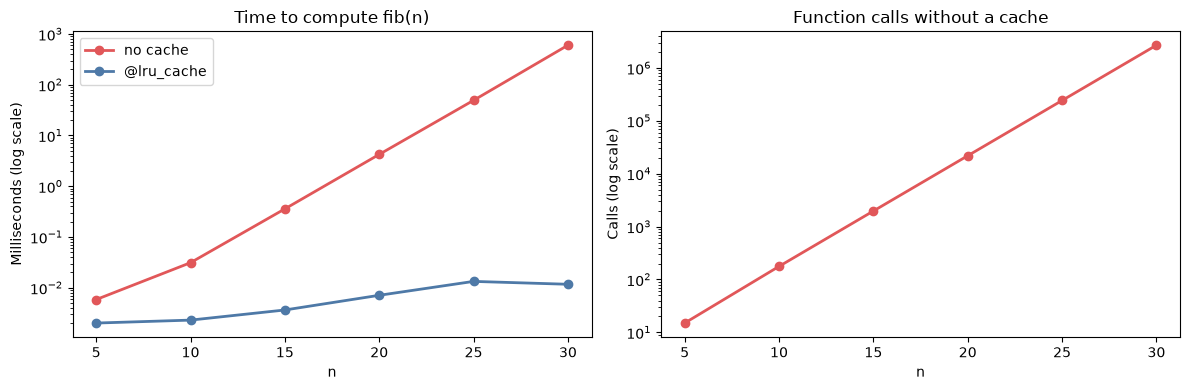

fib(30): 2,692,537 calls, 601 ms without cache vs 0.012 ms with cache


In [4]:
import matplotlib.pyplot as plt

ns = list(range(5, 31, 5))
plain_ms, cached_ms, calls = [], [], []
for n in ns:
    fib.calls = 0
    t = time.perf_counter(); fib(n); plain_ms.append((time.perf_counter() - t) * 1000)
    calls.append(fib.calls)
    fib_cached.cache_clear()
    t = time.perf_counter(); fib_cached(n); cached_ms.append((time.perf_counter() - t) * 1000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ns, plain_ms, marker="o", lw=2, color="#E15759", label="no cache")
ax1.plot(ns, cached_ms, marker="o", lw=2, color="#4E79A7", label="@lru_cache")
ax1.set(yscale="log", title="Time to compute fib(n)", xlabel="n", ylabel="Milliseconds (log scale)")
ax1.legend()
ax2.plot(ns, calls, marker="o", lw=2, color="#E15759")
ax2.set(yscale="log", title="Function calls without a cache", xlabel="n", ylabel="Calls (log scale)")
plt.tight_layout()
plt.show()
print(f"fib(30): {calls[-1]:,} calls, {plain_ms[-1]:.0f} ms without cache vs {cached_ms[-1]:.3f} ms with cache")

## 5. Built-in Decorators in Classes

| Decorator | Purpose |
| :--- | :--- |
| `@property` | a method that looks like an attribute (Lesson 13) |
| `@staticmethod` | a function in the class namespace; no `self` |
| `@classmethod` | receives the class (`cls`); used for alternative constructors |
| `@dataclass` | a class decorator that generates methods (Lesson 14) |

In [5]:
from datetime import date

class Person:
    def __init__(self, name: str, birth_year: int):
        self.name, self.birth_year = name, birth_year

    @classmethod
    def from_string(cls, text: str) -> "Person":     # alternative constructor
        name, year = text.split(",")
        return cls(name.strip(), int(year))

    @staticmethod
    def is_adult(age: int) -> bool:
        return age >= 18

    @property
    def age(self) -> int:
        return date.today().year - self.birth_year

p = Person.from_string("Elif, 2001")
print(p.name, p.age, Person.is_adult(p.age))

Elif 25 True


*Insight: A decorator is the right tool for behaviour that many functions share and that is not part of their main job: timing, logging, caching, retries, authentication. Keep the decorated function focused on its own task.*

## Real-World Use Case or Analogy

A decorator is like a **gift wrapper**: the gift (the function) stays the same, but the wrapper adds something around it. You can wrap the same gift twice: first in paper (logging), then in a box (timing).

Frameworks use decorators heavily: `@app.get("/users")` registers a web endpoint in FastAPI (M30), `@pytest.fixture` defines test set-up (M02), `@torch.no_grad()` turns off gradient tracking (M20), and `@tool` turns a Python function into a tool that an LLM agent can call (M29).